# 01 · Diagnosing a linear regression

A full assumption check of an OLS model on `mtcars`: fuel efficiency (`mpg`) explained by weight and horsepower.

In [1]:
import warnings

import pandas as pd
import statsmodels.api as sm
import statsmodels.formula.api as smf

warnings.filterwarnings("ignore", category=FutureWarning)
DATA = "../tests/data"
mtcars = pd.read_csv(f"{DATA}/mtcars.csv", index_col=0)
fit = smf.ols("mpg ~ wt + hp", data=mtcars).fit()
fit.params

Intercept    37.227270
wt           -3.877831
hp           -0.031773
dtype: float64

## Everything at once

`check_model()` runs the checks that apply to a linear model and prints one verdict per check.

In [2]:
from checkmodel import check_model

report = check_model(fit)
report

# Model checks: OLS (gaussian, identity link), n = 32

Posterior predictive check: OK: Model-predicted data resemble the observed data (mean p = 0.400, sd p = 0.460).
Normality of residuals: Warning: Non-normality of residuals detected (p = 0.021).
Homogeneity of variance: OK: Error variance appears to be homoscedastic (p = 0.402).
Collinearity: OK: Low collinearity (all VIF < 5; max 1.77).
Influential observations: OK: No outliers detected (Cook's distance > 0.808).
Autocorrelation: Warning: Autocorrelated residuals detected (p = 0.041).

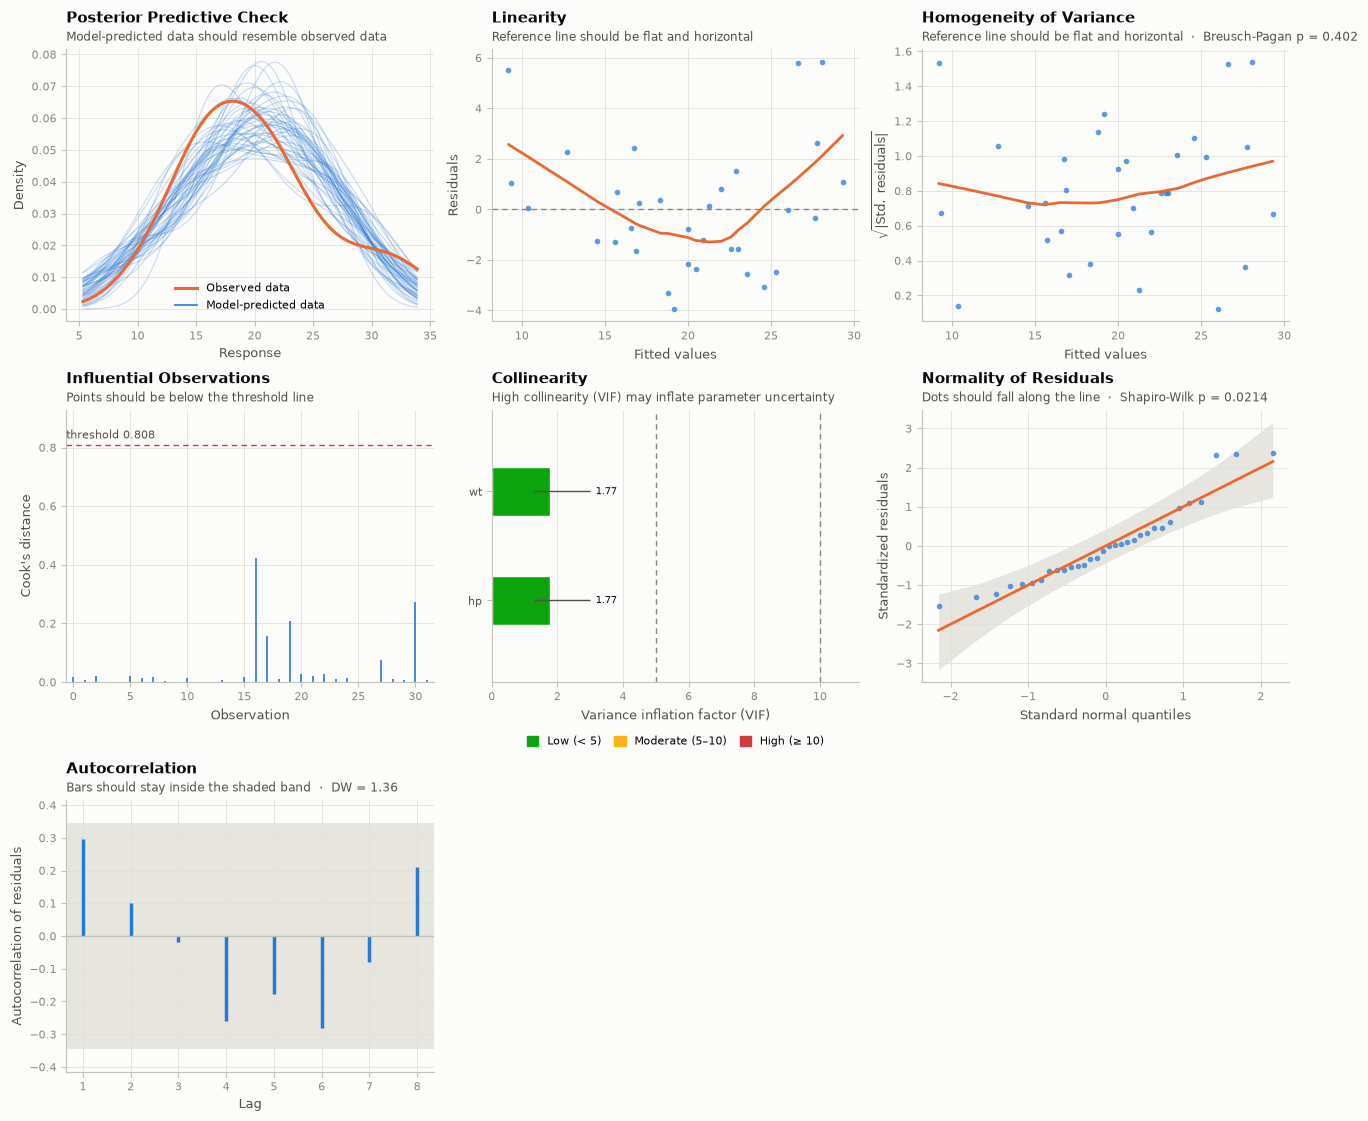

In [3]:
report.plot();

Two warnings: the residuals are not quite normal and look autocorrelated. With 32 cars, read the plots before the p-values: the Q-Q plot shows a few large positive residuals (the curvature also visible in the linearity panel), which suggests a missing non-linear term rather than a broken model.

## One check at a time

Each check returns a result with `.passed`, `.statistic`, `.p_value`, `.to_dataframe()` and `.plot()`.

In [4]:
from checkmodel import check_normality, check_outliers

normality = check_normality(fit)
normality.method, normality.statistic, normality.p_value

('Shapiro-Wilk', 0.9204843530557756, 0.02142904232604338)

In [5]:
normality.plot();

In [6]:
outliers = check_outliers(fit)
outliers.to_dataframe().sort_values("Cooks_Distance", ascending=False).head()

,Cooks_Distance,Leverage,Std_Residual,Outlier
Chrysler Imperial,0.423611,0.186487,2.354517,False
Maserati Bora,0.272040,0.394208,1.119891,False
Toyota Corolla,0.208393,0.099503,2.378618,False
Fiat 128,0.157426,0.079910,2.331923,False
Lotus Europa,0.073540,0.153641,1.102415,False


Cook's distance stays below R's default threshold (the median of an F distribution). The common 4/n rule flags more cars:

In [7]:
check_outliers(fit, threshold="4/n")

## Modelling the curvature

A quadratic term for horsepower captures the bend in the residuals. Centring `hp` first keeps the linear and quadratic terms from being collinear (uncentred, their VIFs exceed 10).

In [8]:
mtcars["hp_c"] = mtcars["hp"] - mtcars["hp"].mean()
curved = smf.ols("mpg ~ wt + hp_c + I(hp_c**2)", data=mtcars).fit()
check_model(curved)

# Model checks: OLS (gaussian, identity link), n = 32

Posterior predictive check: OK: Model-predicted data resemble the observed data (mean p = 0.400, sd p = 0.420).
Normality of residuals: Warning: Non-normality of residuals detected (p = 0.003).
Homogeneity of variance: OK: Error variance appears to be homoscedastic (p = 0.256).
Collinearity: OK: Low collinearity (all VIF < 5; max 3.30).
Influential observations: OK: No outliers detected (Cook's distance > 0.808).
Autocorrelation: OK: Residuals appear to be independent and not autocorrelated (p = 0.329).

The autocorrelation warning is gone: it came from the curvature, because similar cars sit next to each other in `mtcars`, so their residuals line up. Normality still fails, driven by the few largest residuals; with 32 observations that is a reason to look at the Q-Q plot, not necessarily to change the model.